# Classical Machine Learning — Driver-Based Validation

## 1. Load Training and Validation Data

Evaluate selected classical ML models on unseen validation drivers.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

ROOT = Path("..")

# Load training and validation metadata
train_df = pd.read_csv(
    ROOT / "data/splits/driver_based/train.csv"
)

val_df = pd.read_csv(
    ROOT / "data/splits/driver_based/val.csv"
)

# Load ONLY 128x96 HOG features
X_train = np.load(
    ROOT / "data/processed/driver_based/hog_128x96_train.npy",
    mmap_mode="r"
)

X_val = np.load(
    ROOT / "data/processed/driver_based/hog_128x96_val.npy",
    mmap_mode="r"
)

# Load labels
y_train = train_df["classname"].to_numpy()
y_val = val_df["classname"].to_numpy()

# Verify dimensions
assert X_train.shape == (len(train_df), 5940)
assert X_val.shape == (len(val_df), 5940)

# Verify no driver overlap
assert set(train_df["subject"]).isdisjoint(set(val_df["subject"]))

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)

print("Training drivers:", train_df["subject"].nunique())
print("Validation drivers:", val_df["subject"].nunique())

print("\nDataset ready for validation!")

Training features: (15732, 5940)
Validation features: (3603, 5940)
Training drivers: 18
Validation drivers: 4

Dataset ready for validation!


## 2. Logistic Regression — Training and Validation

Train the selected classical ML model using all 18 training drivers.

Evaluate its generalization performance on 4 unseen validation drivers.

Save the trained model, evaluation metrics, confusion matrix,
hyperparameters, and execution times.

In [2]:
import json
import time
import platform
import sklearn

from datetime import datetime, timezone
from joblib import dump

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# 1. Create the same Logistic Regression pipeline used in CV
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])


# 2. Train on all 18 training drivers
started_at = datetime.now(timezone.utc).isoformat()

start = time.perf_counter()

lr_model.fit(X_train, y_train)

train_time = time.perf_counter() - start


# 3. Predict on 4 unseen validation drivers
start = time.perf_counter()

y_pred = lr_model.predict(X_val)

prediction_time = time.perf_counter() - start

completed_at = datetime.now(timezone.utc).isoformat()


# 4. Evaluate model performance
accuracy = accuracy_score(y_val, y_pred)
macro_f1 = f1_score(y_val, y_pred, average="macro")

labels = sorted(np.unique(y_train).tolist())

report = classification_report(
    y_val,
    y_pred,
    labels=labels,
    output_dict=True,
    zero_division=0
)

cm = confusion_matrix(y_val, y_pred, labels=labels)


# 5. Create output directories
results_dir = ROOT / "results/classical/driver_based/validation"
model_dir = ROOT / "models/classical/driver_based"

results_dir.mkdir(parents=True, exist_ok=True)
model_dir.mkdir(parents=True, exist_ok=True)


# 6. Save trained model
model_path = model_dir / "logistic_regression_128x96.joblib"

dump(lr_model, model_path)


# 7. Save confusion matrix
cm_df = pd.DataFrame(cm, index=labels, columns=labels)

cm_path = results_dir / "logistic_regression_128x96_confusion_matrix.csv"
cm_df.to_csv(cm_path)


# 8. Save detailed validation metadata
metadata = {
    "experiment": {
        "model": "Logistic Regression",
        "resolution": "128x96",
        "feature_type": "HOG",
        "evaluation_type": "Held-out driver validation",
        "started_at": started_at,
        "completed_at": completed_at
    },

    "dataset": {
        "training_images": int(len(y_train)),
        "validation_images": int(len(y_val)),
        "training_drivers": sorted(train_df["subject"].unique().tolist()),
        "validation_drivers": sorted(val_df["subject"].unique().tolist()),
        "driver_overlap": 0,
        "hog_features": int(X_train.shape[1]),
        "classes": labels
    },

    "model_configuration": {
        "pipeline": ["StandardScaler", "LogisticRegression"],
        "scaler_parameters": lr_model.named_steps["scaler"].get_params(),
        "logistic_regression_parameters": lr_model.named_steps["logreg"].get_params()
    },

    "results": {
        "accuracy": float(accuracy),
        "macro_f1": float(macro_f1),
        "classification_report": report,
        "confusion_matrix": cm.tolist(),
        "confusion_matrix_labels": labels
    },

    "timing": {
        "training_seconds": float(train_time),
        "prediction_seconds": float(prediction_time),
        "total_execution_seconds": float(train_time + prediction_time)
    },

    "environment": {
        "python_version": platform.python_version(),
        "sklearn_version": sklearn.__version__,
        "operating_system": platform.platform()
    },

    "saved_model": str(model_path)
}


# 9. Save JSON
json_path = results_dir / "logistic_regression_128x96_validation.json"

with open(json_path, "w") as f:
    json.dump(metadata, f, indent=4)


# 10. Display results
print("Logistic Regression — 128x96 Validation Results")

print(f"\nValidation Accuracy: {accuracy:.4f}")
print(f"Validation Macro-F1: {macro_f1:.4f}")

print(f"\nTraining time: {train_time:.2f} seconds")
print(f"Prediction time: {prediction_time:.2f} seconds")

print("\nClassification Report:")
print(classification_report(
    y_val, y_pred, labels=labels, zero_division=0
))

print("\nModel saved:", model_path)
print("JSON saved:", json_path)
print("Confusion matrix saved:", cm_path)

print("\nValidation experiment completed successfully!")

Logistic Regression — 128x96 Validation Results

Validation Accuracy: 0.5171
Validation Macro-F1: 0.5057

Training time: 3.93 seconds
Prediction time: 0.07 seconds

Classification Report:
              precision    recall  f1-score   support

          c0       0.52      0.30      0.38       372
          c1       0.83      0.67      0.74       377
          c2       0.50      0.44      0.47       367
          c3       0.36      0.75      0.48       393
          c4       0.48      0.33      0.39       378
          c5       0.53      0.72      0.61       372
          c6       0.94      0.51      0.66       372
          c7       0.63      0.93      0.75       342
          c8       0.61      0.37      0.46       298
          c9       0.11      0.10      0.11       332

    accuracy                           0.52      3603
   macro avg       0.55      0.51      0.51      3603
weighted avg       0.55      0.52      0.51      3603


Model saved: ../models/classical/driver_based/logist

## 3. Error Analysis — Confusion Matrix

Analyze classification mistakes on the held-out validation drivers.

Identify which distracted-driving activities are most frequently confused.

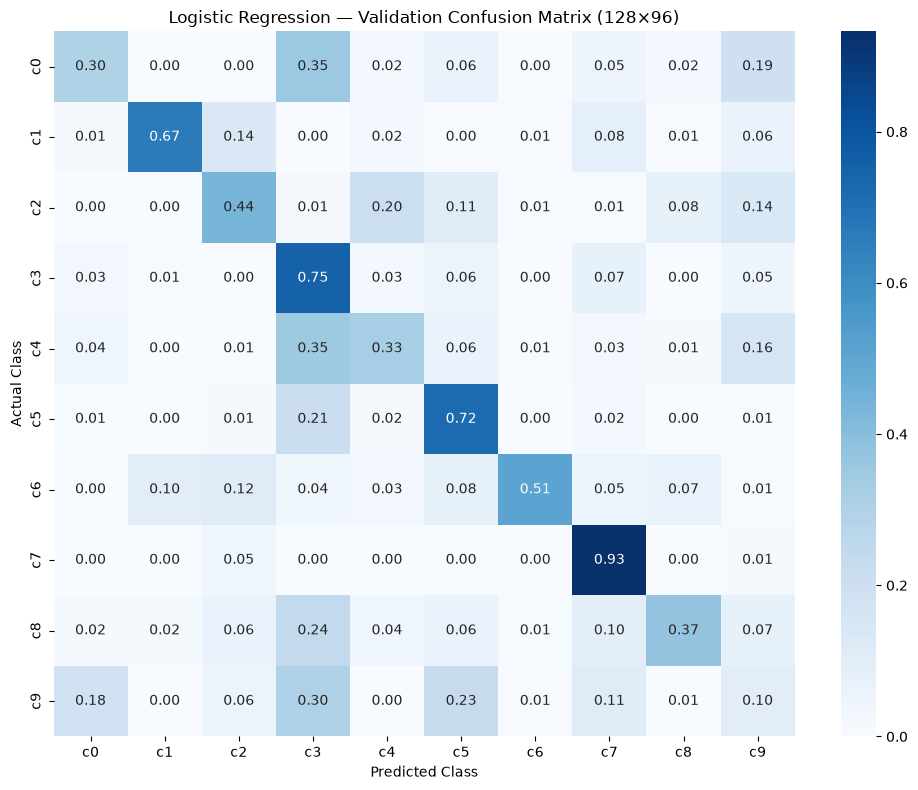

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm = confusion_matrix(y_val, y_pred, labels=labels)

# Normalize by actual class
cm_normalized = confusion_matrix(
    y_val,
    y_pred,
    labels=labels,
    normalize="true"
)

# Plot normalized confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Logistic Regression — Validation Confusion Matrix (128×96)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

## 5. Visual Error Analysis — Misclassified Images

Investigate the most frequent classification errors.

Examine original validation images and model prediction confidence
to understand why certain driving activities are difficult to classify.

In [5]:
import numpy as np
import pandas as pd
from pathlib import Path
from joblib import load

# Load the saved model if necessary
model_path = ROOT / "models/classical/driver_based/logistic_regression_128x96.joblib"

if "lr_model" not in globals():
    lr_model = load(model_path)

# 1. Obtain prediction probabilities
probabilities = lr_model.predict_proba(X_val)

classes = lr_model.classes_
predictions = lr_model.predict(X_val)

# 2. Create detailed predictions dataframe
error_df = val_df.reset_index(drop=True).copy()

error_df["actual"] = y_val
error_df["predicted"] = predictions

error_df["correct"] = (
    error_df["actual"] == error_df["predicted"]
)

# Probability assigned to predicted class
error_df["confidence"] = probabilities.max(axis=1)

# Probability assigned to actual class
class_to_idx = {c: i for i, c in enumerate(classes)}

actual_indices = np.array([
    class_to_idx[c] for c in y_val
])

error_df["actual_class_probability"] = probabilities[
    np.arange(len(y_val)),
    actual_indices
]

# 3. Separate incorrect predictions
errors = error_df[~error_df["correct"]].copy()

print("Total validation images:", len(error_df))
print("Correct predictions:", error_df["correct"].sum())
print("Incorrect predictions:", len(errors))

print("\nMost frequent classification mistakes:")

confusions = (
    errors.groupby(["actual", "predicted"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

print(confusions.head(15).to_string(index=False))

# 4. Save detailed predictions
error_dir = results_dir / "error_analysis"
error_dir.mkdir(parents=True, exist_ok=True)

error_df.to_csv(
    error_dir / "validation_predictions.csv",
    index=False
)

confusions.to_csv(
    error_dir / "class_confusions.csv",
    index=False
)

print("\nError analysis data saved!")

Total validation images: 3603
Correct predictions: 1863
Incorrect predictions: 1740

Most frequent classification mistakes:
actual predicted  count
    c4        c3    133
    c0        c3    132
    c9        c3    100
    c5        c3     78
    c9        c5     77
    c2        c4     75
    c8        c3     73
    c0        c9     72
    c4        c9     61
    c9        c0     60
    c1        c2     52
    c2        c9     51
    c6        c2     43
    c2        c5     39
    c9        c7     38

Error analysis data saved!


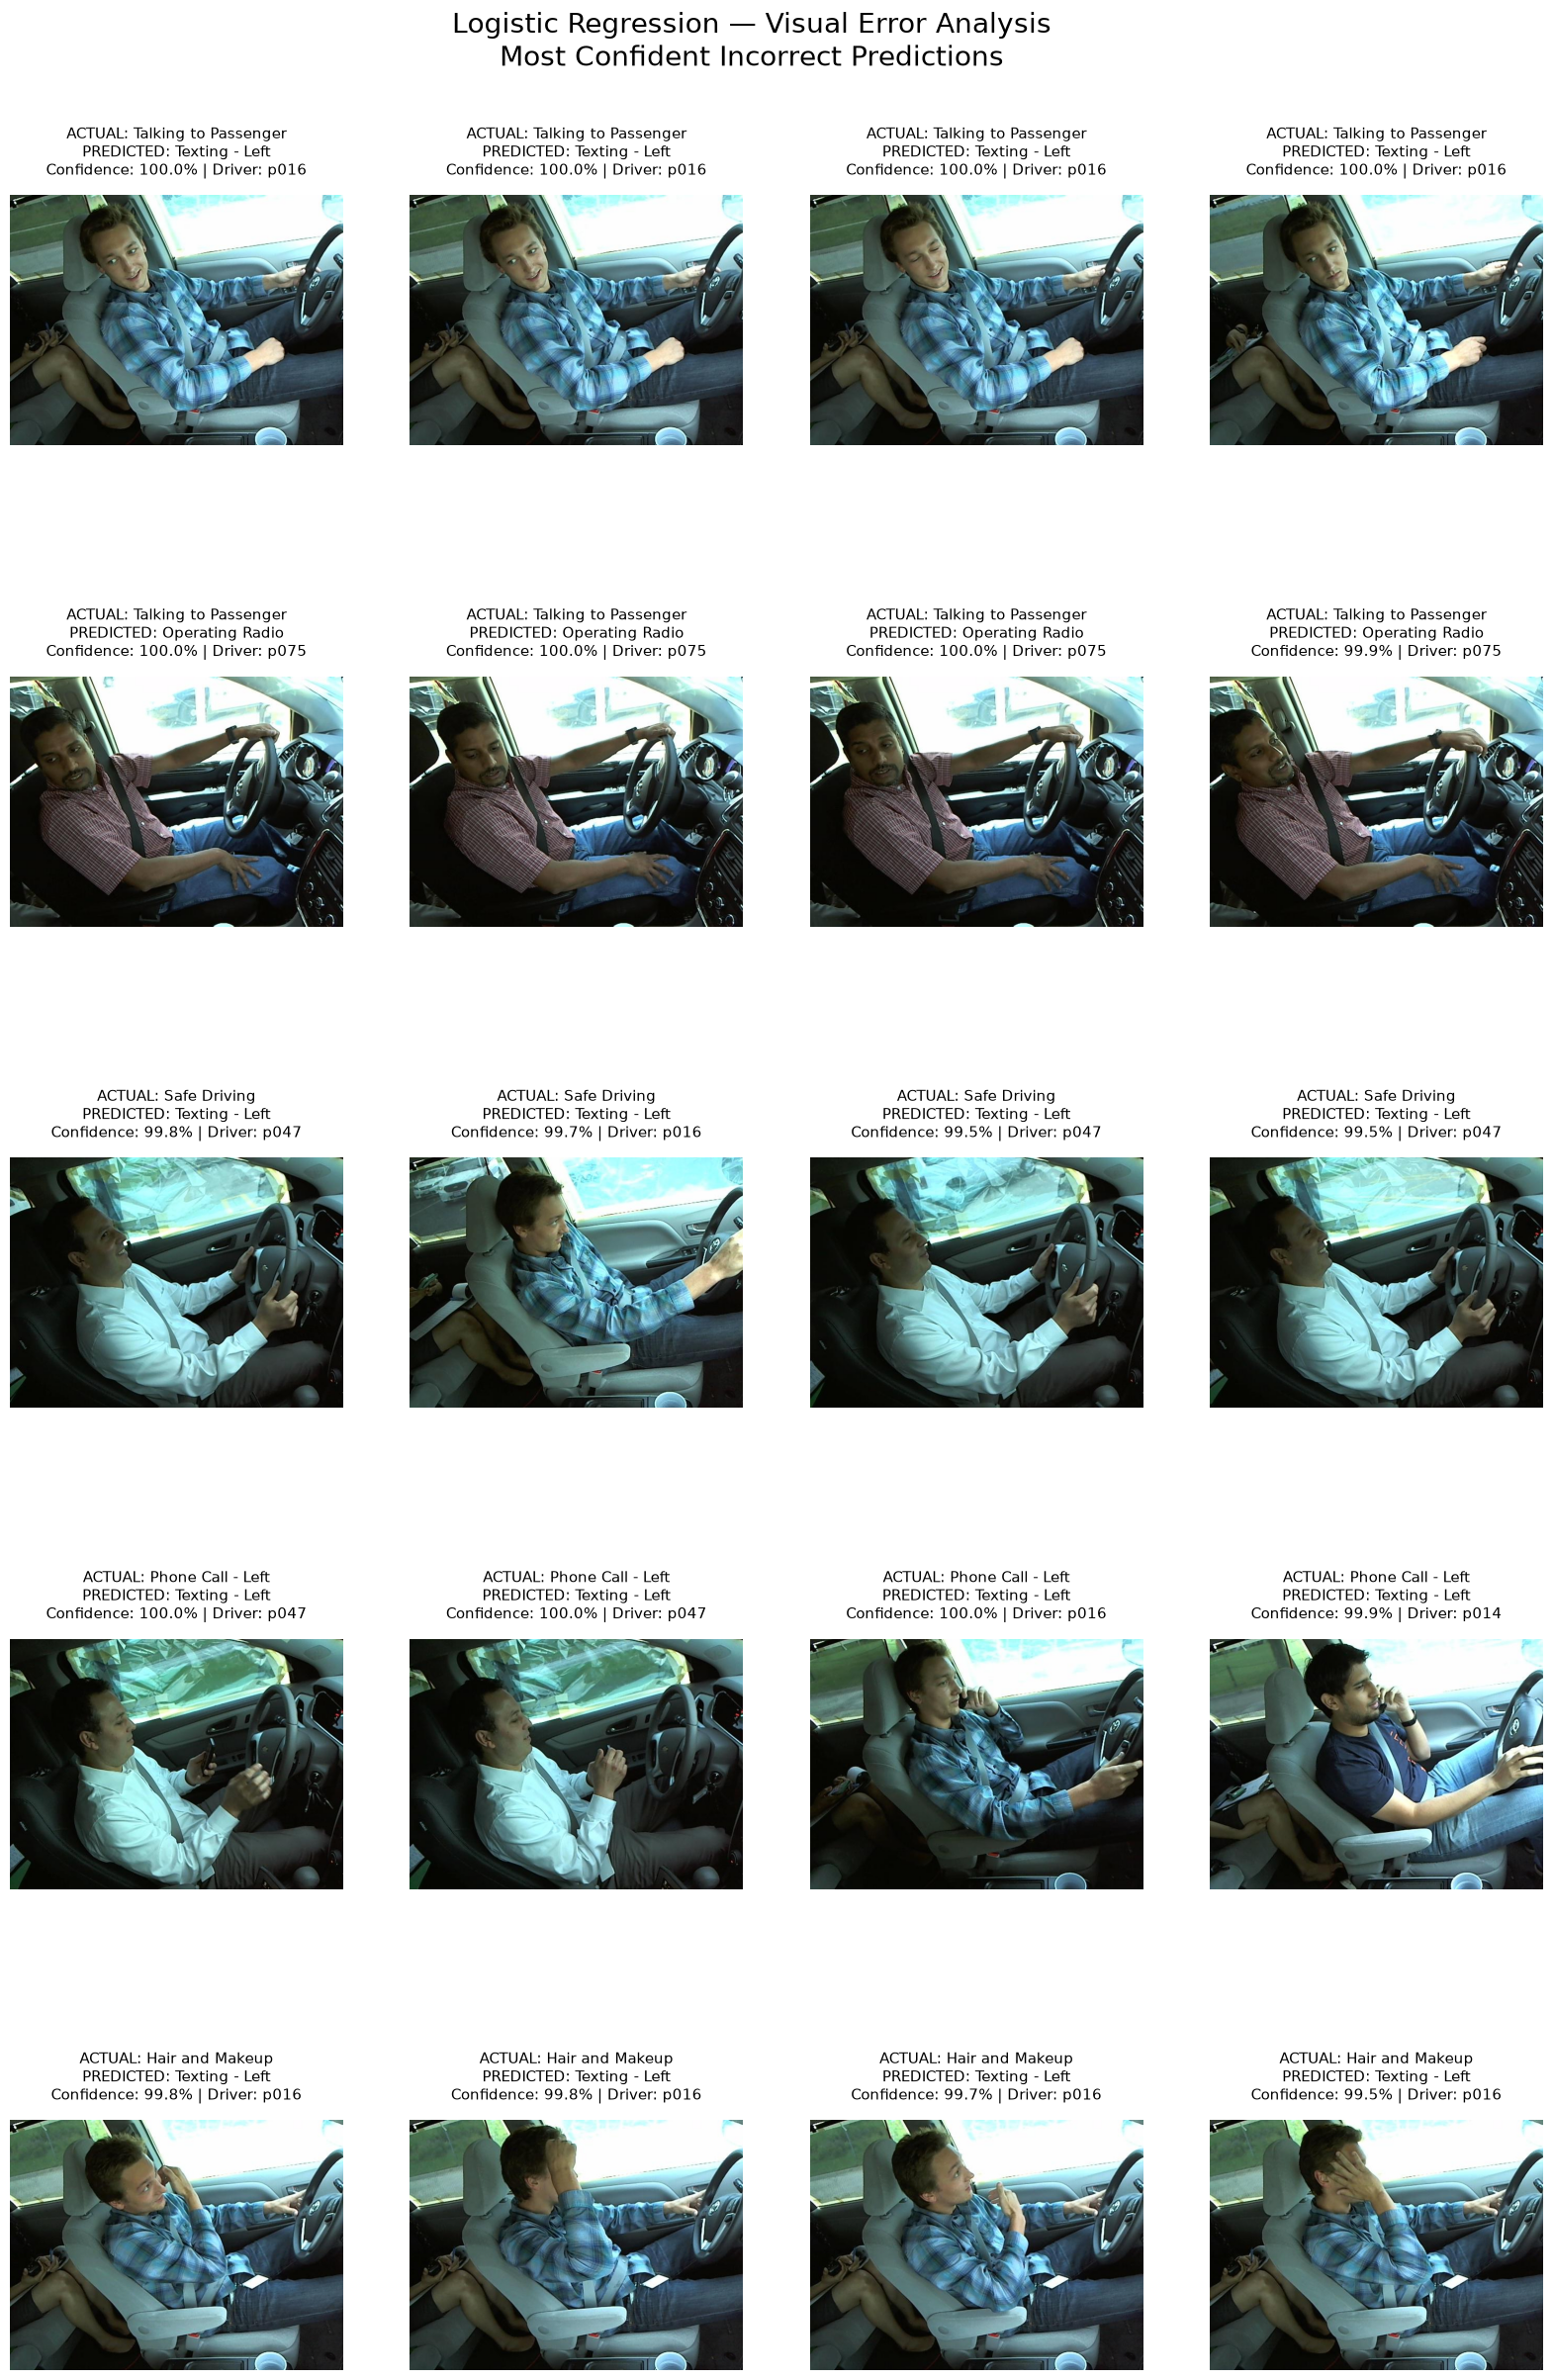

Visualization saved: ../results/classical/driver_based/validation/error_analysis/most_confident_errors.png


In [7]:
import matplotlib.pyplot as plt

# Common classification mistakes
error_pairs = [
    ("c9", "c3"),
    ("c9", "c5"),
    ("c0", "c3"),
    ("c4", "c3"),
    ("c8", "c3")
]

# Display class names
class_names = {
    "c0": "Safe Driving",
    "c1": "Texting - Right",
    "c2": "Phone Call - Right",
    "c3": "Texting - Left",
    "c4": "Phone Call - Left",
    "c5": "Operating Radio",
    "c6": "Drinking",
    "c7": "Reaching Behind",
    "c8": "Hair and Makeup",
    "c9": "Talking to Passenger"
}

image_dir = ROOT / "data/raw/imgs/train"

# Larger figure with additional vertical spacing
fig, axes = plt.subplots(
    5, 4,
    figsize=(20, 25)
)

for row_idx, (actual, predicted) in enumerate(error_pairs):

    subset = errors[
        (errors["actual"] == actual) &
        (errors["predicted"] == predicted)
    ]

    # Four most confident incorrect predictions
    subset = (
        subset.sort_values("confidence", ascending=False)
        .head(4)
        .reset_index(drop=True)
    )

    for col_idx in range(4):

        ax = axes[row_idx, col_idx]

        if col_idx >= len(subset):
            ax.axis("off")
            continue

        sample = subset.iloc[col_idx]

        image_path = (
            image_dir /
            sample["classname"] /
            sample["img"]
        )

        image = plt.imread(image_path)

        ax.imshow(image)

        # Display details ABOVE the image
        ax.set_title(
            f"ACTUAL: {class_names[sample['actual']]}\n"
            f"PREDICTED: {class_names[sample['predicted']]}\n"
            f"Confidence: {sample['confidence']:.1%} | "
            f"Driver: {sample['subject']}",
            fontsize=11,
            pad=15
        )

        ax.axis("off")

# Add overall title
fig.suptitle(
    "Logistic Regression — Visual Error Analysis\n"
    "Most Confident Incorrect Predictions",
    fontsize=20,
    y=0.995
)

# Increase spacing between rows
plt.subplots_adjust(
    hspace=0.6,
    wspace=0.2,
    top=0.93,
    bottom=0.03
)

# Save visualization
save_path = error_dir / "most_confident_errors.png"

plt.savefig(
    save_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Visualization saved:", save_path)

### Common Classification Errors and Visual Ambiguity

We conducted a detailed error analysis of the HOG-based Logistic Regression classifier on 3,603 validation images from four unseen drivers. The model correctly classified 1,863 images and incorrectly classified 1,740, achieving 51.71% accuracy.

The most frequent classification error was confusing talking on the phone with the left hand (c4) with texting using the left hand (c3), occurring in 133 images. Safe driving (c0) was also frequently misclassified as texting with the left hand (132 images), followed by talking to a passenger (c9), with 100 such errors.

A notable pattern was the frequent incorrect prediction of class c3 across multiple activities. Five common confusion categories involving c3 accounted for 516 errors, representing approximately 29.7% of all misclassifications.

The classifier also struggled to recognize talking to passengers (c9), which achieved approximately 10% recall. Images belonging to this category were frequently classified as texting, operating the radio, or safe driving.

Additionally, the model confused talking on the phone using the right hand (c2) with talking on the phone using the left hand (c4) in 75 instances, suggesting difficulty distinguishing subtle spatial differences between otherwise similar activities.

Visual inspection revealed that several misclassified activities involved overlapping arm positions, head orientations, and upper-body configurations. These observations suggest that fixed HOG descriptors and linear decision boundaries may be insufficient for reliably distinguishing complex driving activities.

These findings motivate evaluating convolutional neural networks, which can learn nonlinear, hierarchical image representations and potentially capture more discriminative relationships between body posture, hand placement, and object interactions.

## 6. Detailed Error Analysis — Talking to Passenger (c9)

Investigate why the model struggles to recognize passenger conversations.

Compare incorrect and correct predictions across validation drivers.

Actual Activity: Talking to Passenger (c9)
Total images: 332
Correct predictions: 33
Incorrect predictions: 299

Prediction Distribution:
  Predicted Activity  Count  Percentage
        Safe Driving     60       18.07
     Texting - Right      1        0.30
  Phone Call - Right     19        5.72
      Texting - Left    100       30.12
   Phone Call - Left      0        0.00
     Operating Radio     77       23.19
            Drinking      2        0.60
     Reaching Behind     38       11.45
     Hair and Makeup      2        0.60
Talking to Passenger     33        9.94


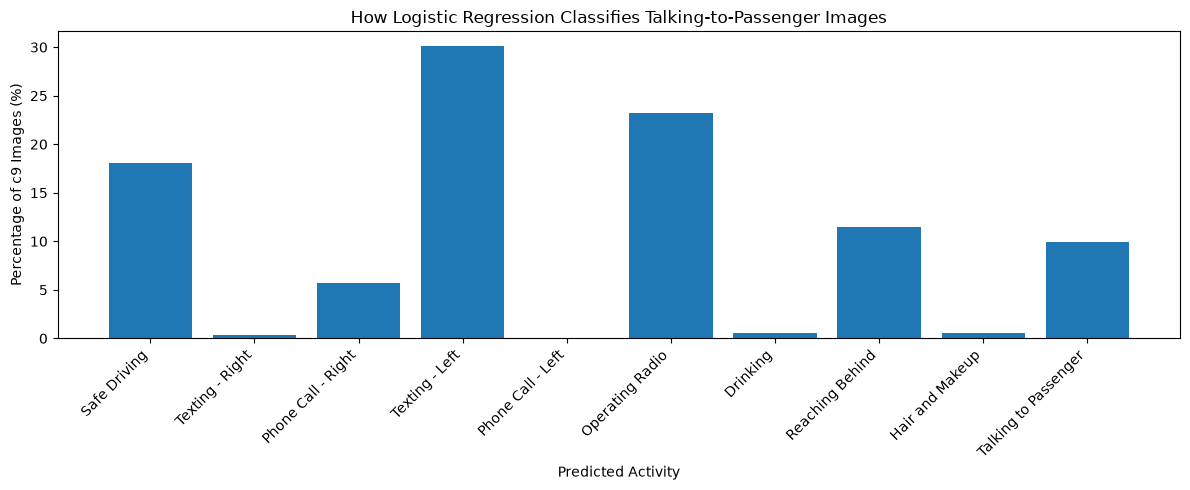

In [8]:
# Select only c9 validation images
c9_df = error_df[error_df["actual"] == "c9"].copy()

# Count predictions for each class
c9_counts = (
    c9_df["predicted"]
    .value_counts()
    .reindex(sorted(class_names.keys()), fill_value=0)
)

# Calculate prediction percentages
c9_percentages = c9_counts / len(c9_df) * 100

c9_results = pd.DataFrame({
    "Predicted Activity": [
        class_names[c] for c in c9_counts.index
    ],
    "Count": c9_counts.values,
    "Percentage": c9_percentages.values
})

print("Actual Activity: Talking to Passenger (c9)")
print("Total images:", len(c9_df))
print("Correct predictions:", c9_df["correct"].sum())
print("Incorrect predictions:", (~c9_df["correct"]).sum())

print("\nPrediction Distribution:")
print(c9_results.round(2).to_string(index=False))

# Visualize prediction distribution
plt.figure(figsize=(12, 5))

plt.bar(
    c9_results["Predicted Activity"],
    c9_results["Percentage"]
)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Percentage of c9 Images (%)")
plt.xlabel("Predicted Activity")
plt.title("How Logistic Regression Classifies Talking-to-Passenger Images")

plt.tight_layout()
plt.show()

# Save results
c9_results.to_csv(
    error_dir / "c9_prediction_distribution.csv",
    index=False
)

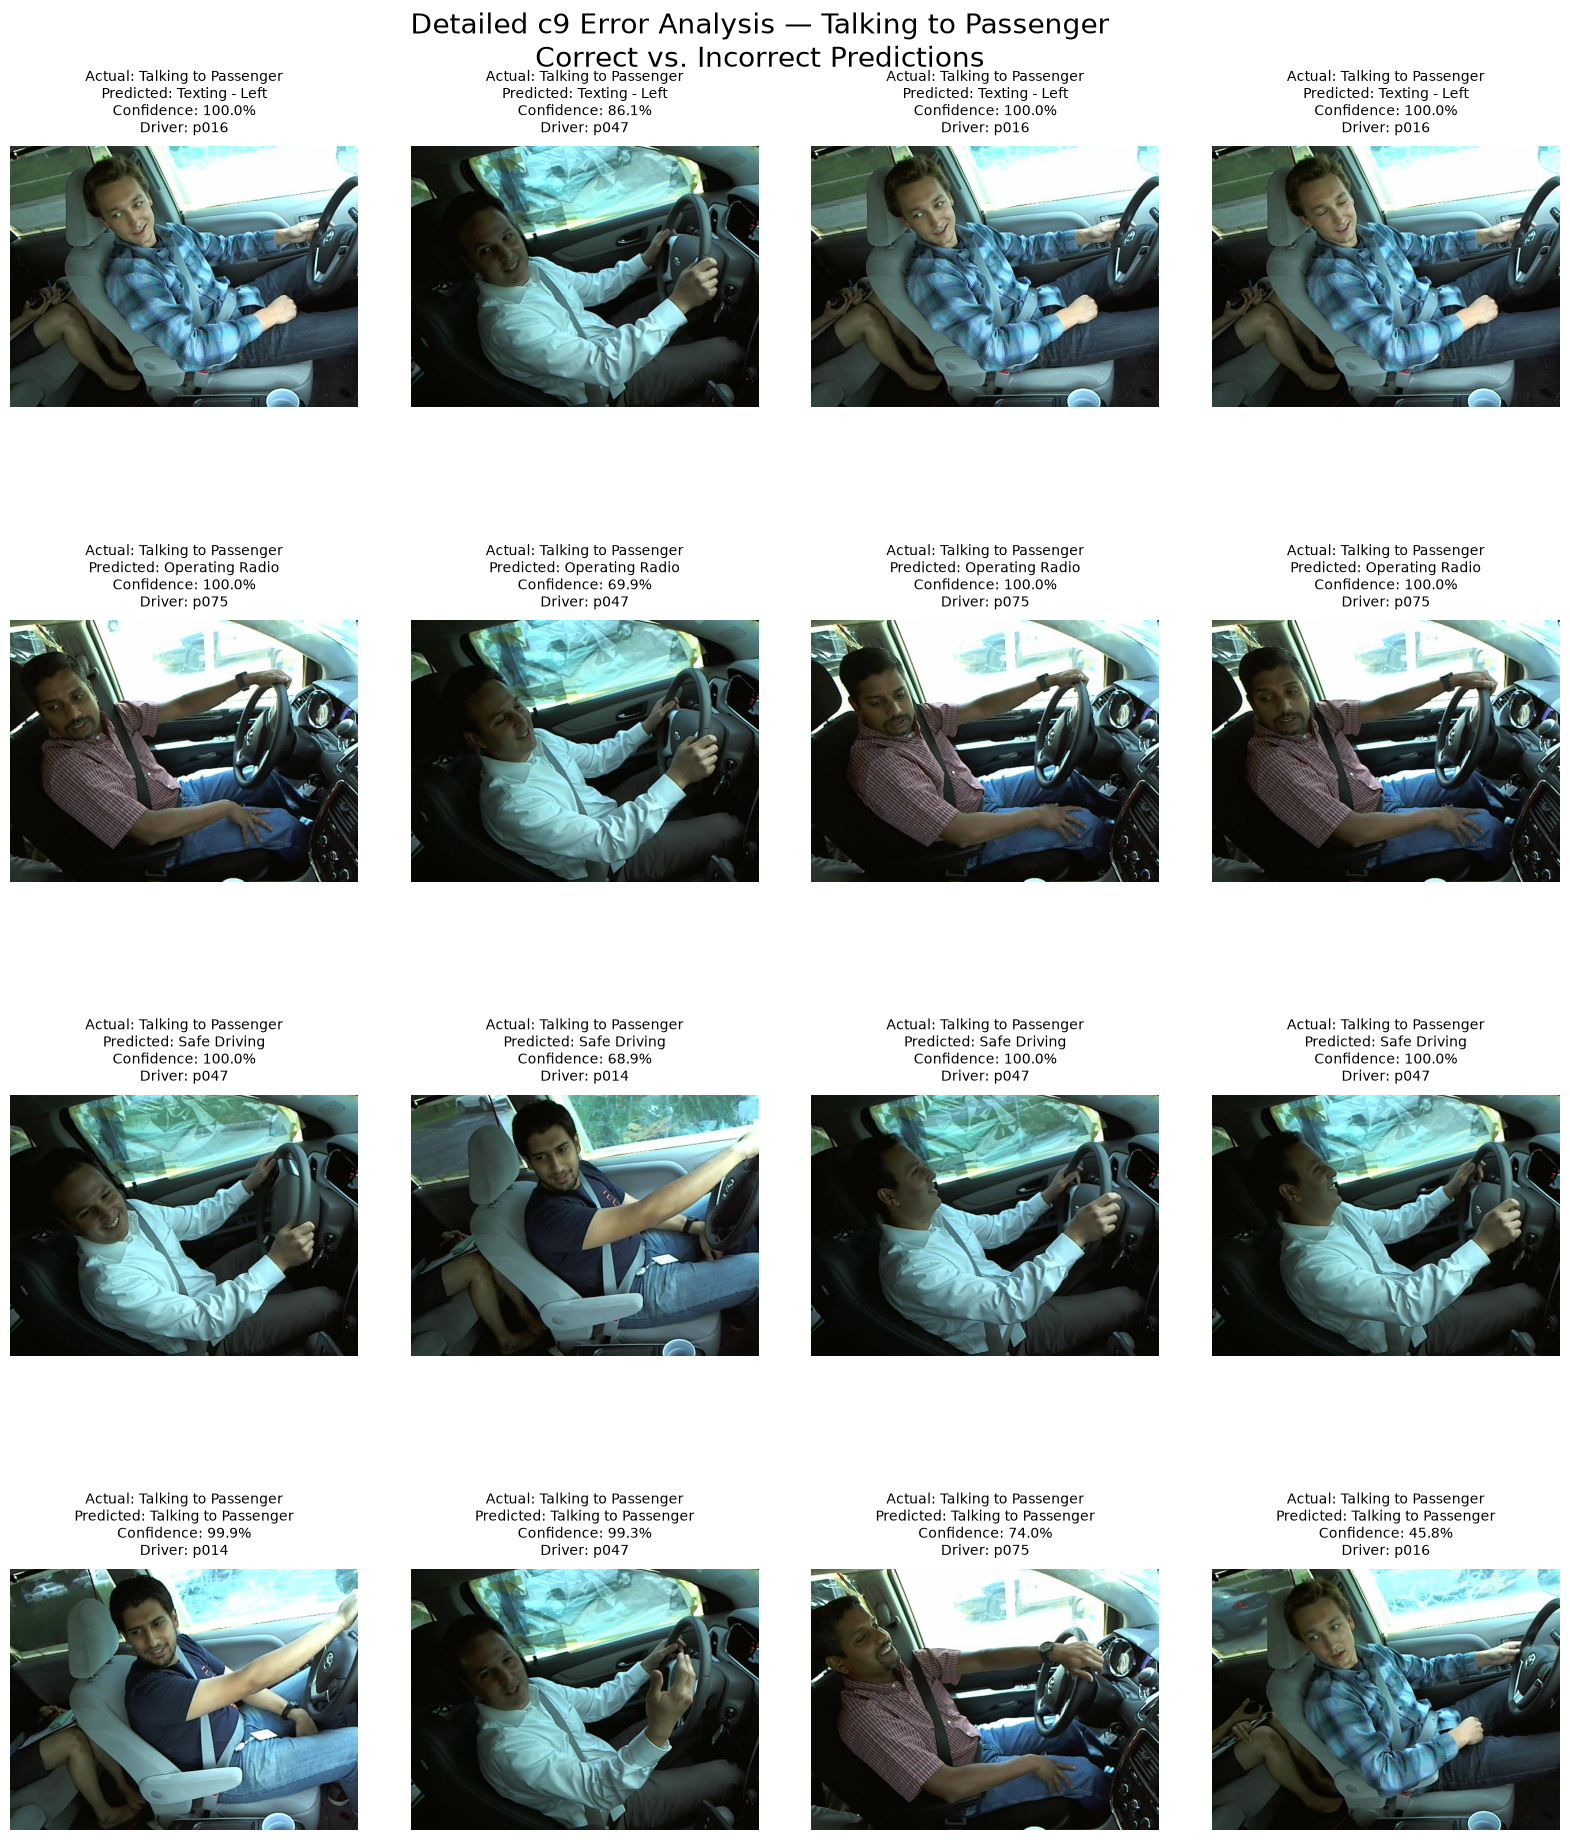

Saved: ../results/classical/driver_based/validation/error_analysis/c9_detailed_error_analysis.png


In [9]:
import matplotlib.pyplot as plt

image_dir = ROOT / "data/raw/imgs/train"

# c9 prediction categories
prediction_groups = [
    ("c3", "Mistake: Texting - Left"),
    ("c5", "Mistake: Operating Radio"),
    ("c0", "Mistake: Safe Driving"),
    ("c9", "Correct: Talking to Passenger")
]

fig, axes = plt.subplots(
    4, 4,
    figsize=(20, 19)
)

for row_idx, (predicted_class, description) in enumerate(prediction_groups):

    # Get c9 images assigned to this prediction
    subset = c9_df[
        c9_df["predicted"] == predicted_class
    ].copy()

    # Sort by model confidence
    subset = subset.sort_values(
        "confidence",
        ascending=False
    )

    # Prefer one image per driver for visual diversity
    diverse_samples = subset.drop_duplicates(
        subset="subject",
        keep="first"
    )

    # Fill any remaining slots with other images
    remaining = subset.loc[
        ~subset.index.isin(diverse_samples.index)
    ]

    selected = pd.concat([
        diverse_samples,
        remaining
    ]).head(4)

    selected = selected.reset_index(drop=True)

    for col_idx in range(4):

        ax = axes[row_idx, col_idx]

        if col_idx >= len(selected):
            ax.axis("off")
            continue

        sample = selected.iloc[col_idx]

        image_path = (
            image_dir /
            sample["classname"] /
            sample["img"]
        )

        image = plt.imread(image_path)

        ax.imshow(image)

        ax.set_title(
            f"Actual: Talking to Passenger\n"
            f"Predicted: {class_names[sample['predicted']]}\n"
            f"Confidence: {sample['confidence']:.1%}\n"
            f"Driver: {sample['subject']}",
            fontsize=10,
            pad=10
        )

        ax.axis("off")

    # Add row description
    axes[row_idx, 0].set_ylabel(
        description,
        fontsize=12
    )

fig.suptitle(
    "Detailed c9 Error Analysis — Talking to Passenger\n"
    "Correct vs. Incorrect Predictions",
    fontsize=20,
    y=0.995
)

plt.subplots_adjust(
    hspace=0.65,
    wspace=0.15,
    top=0.93,
    bottom=0.03
)

# Save visualization
save_path = error_dir / "c9_detailed_error_analysis.png"

plt.savefig(
    save_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)

# Error Analysis and Discussion: Classification of Passenger Interaction

## 1. Experimental Context

We conducted a detailed error analysis of a classical machine learning approach for distracted driving detection using Histogram of Oriented Gradients (HOG) features and Logistic Regression.

The model was trained on 15,732 images belonging to 18 drivers and evaluated on a separate validation dataset containing 3,603 images from four previously unseen drivers.

Images were resized to 128 × 96 pixels and represented using 5,940 HOG features. The classifier consisted of a StandardScaler followed by Logistic Regression with a maximum of 1,000 iterations.

The model achieved the following performance:

| Evaluation Metric | Result |
|---|---:|
| Four-fold cross-validation accuracy | 61.05% |
| Four-fold cross-validation Macro-F1 | 61.09% |
| Held-out validation accuracy | 51.71% |
| Held-out validation Macro-F1 | 50.57% |
| Correct validation predictions | 1,863 |
| Incorrect validation predictions | 1,740 |

The decrease in performance on previously unseen drivers suggests challenges with generalizing learned visual patterns across individuals.

To better understand these limitations, we examined the confusion matrix and conducted a qualitative inspection of misclassified images.

Particular attention was given to class c9 (Talking to Passenger), which exhibited the lowest recall among the ten driving activity classes.

---

## 2. Quantitative Analysis of Class c9

Class c9 represents a driver talking to a passenger.

The validation dataset contains 332 images belonging to this category.

The classifier achieved approximately:

| Metric | Class c9 |
|---|---:|
| Total validation images | 332 |
| Recall | 10% |
| Precision | 11% |
| F1-score | 11% |
| Incorrect classification rate | 90% |

These results indicate that approximately nine out of every ten passenger-interaction images were assigned to another activity.

### 2.1 Most Frequent Confusions

The confusion matrix revealed the following major classification errors:

| Actual Activity | Predicted Activity | Incorrect Images | Percentage of c9 Images |
|---|---|---:|---:|
| Talking to Passenger | Texting with Left Hand | 100 | 30.1% |
| Talking to Passenger | Operating Radio | 77 | 23.2% |
| Talking to Passenger | Safe Driving | 60 | 18.1% |
| Talking to Passenger | Reaching Behind | 38 | 11.4% |

Together, these four confusion categories account for 275 images, representing approximately 82.8% of all c9 validation images.

The findings demonstrate that the classifier does not consistently associate passenger interaction with a distinctive visual representation.

Instead, c9 images are assigned to several activities involving different arm positions, body orientations, and interactions within the vehicle.

---

## 3. Qualitative Analysis of Misclassified Images

### 3.1 Talking to Passenger Misclassified as Texting

The most frequent c9 confusion occurred when passenger interaction was classified as texting using the left hand.

This mistake occurred in 100 validation images.

Visual inspection revealed examples in which drivers turned their heads toward the passenger while keeping one hand on the steering wheel and another near their laps.

For example, several images belonging to driver p016 were incorrectly classified as texting with nearly 100% reported confidence.

In these images, the driver's body orientation and arm positions may resemble configurations encountered in the texting category.

However, the images do not necessarily contain a visible phone or clear texting gesture.

This suggests that the classifier may associate certain body configurations with texting without sufficiently distinguishing the broader context of the activity.

A possible explanation is that HOG descriptors capture local edge structures but do not explicitly represent relationships among the driver's head, hands, and objects.

Because Logistic Regression learns a linear decision boundary over these fixed features, it may struggle to distinguish activities that share similar geometric patterns.

Nevertheless, additional feature attribution experiments would be necessary to establish which visual regions actually influenced these predictions.

### 3.2 Talking to Passenger Misclassified as Operating Radio

The second most frequent confusion involved operating the radio, accounting for 77 incorrect images.

Several examples showed drivers turning toward the passenger while positioning an arm near the dashboard or center console.

This configuration can visually resemble someone reaching toward vehicle controls.

The challenge is that both activities may involve similar arm placement and upper-body orientation.

However, other incorrectly classified examples showed hands on the steering wheel without an obvious radio interaction.

This suggests that the errors cannot be attributed solely to similarity in hand position.

Additional visual characteristics, including background structure, head orientation, and driver appearance, may contribute to the classification decision.

This finding illustrates the difficulty of distinguishing semantically different activities using only fixed gradient-based image representations.

### 3.3 Talking to Passenger Misclassified as Safe Driving

Another significant confusion occurred between passenger interaction and safe driving.

The model classified 60 c9 images as safe driving.

In several examples, drivers maintained both hands on or near the steering wheel while turning their heads toward the passenger.

From a static image, these postures can resemble normal driving.

The primary distinction may depend on gaze direction, head orientation, and whether the driver is interacting with someone outside the forward roadway.

The HOG-based representation does not explicitly encode the driver's attention or conversational behavior.

This creates a classification challenge when the relevant difference involves subtle visual relationships rather than large changes in body posture.

Furthermore, talking to a passenger is not always directly observable from a single image. Visual evidence of conversation may be limited, even when the dataset label is correct.

Therefore, some classification ambiguity may originate from the nature of the task rather than the limitations of a specific classifier.

---

## 4. Analysis of Correctly Classified Passenger Interactions

We also examined c9 images that were correctly classified.

These examples included drivers p014, p047, p075, and p016.

Several correctly classified images showed drivers turning their heads toward the passenger, gesturing with their hands, or displaying an upper-body orientation consistent with passenger interaction.

Some correct predictions received confidence values above 99%, while others received lower confidence values.

For example, one correctly classified example from driver p016 received approximately 45.8% confidence.

These observations indicate that the classifier can recognize some passenger-interaction configurations.

However, a major finding is that similar head orientations and body positions appeared in both correctly and incorrectly classified examples.

This suggests that the model's decisions may depend on combinations of visual features rather than a single distinctive gesture.

The available examples do not establish which specific features are responsible for correct recognition.

A more systematic comparison of correctly and incorrectly classified images would be needed to identify the most influential patterns.

---

## 5. High-Confidence Classification Errors

One particularly notable finding was the presence of highly confident incorrect predictions.

Several c9 images were assigned to texting, operating the radio, or safe driving with displayed probabilities approaching 100%.

For example:

| Actual Activity | Predicted Activity | Example Confidence |
|---|---|---:|
| Talking to Passenger | Texting with Left Hand | 100% |
| Talking to Passenger | Operating Radio | 100% |
| Talking to Passenger | Safe Driving | 100% |

These values indicate that the model assigned very high predicted probabilities to incorrect classes.

However, predicted probabilities from Logistic Regression are not necessarily calibrated measures of correctness.

The observed errors motivate additional analysis of prediction confidence and model calibration.

Potential evaluation methods include reliability diagrams, Expected Calibration Error (ECE), and comparisons of confidence distributions between correct and incorrect predictions.

Such analyses could determine whether the model systematically produces overconfident predictions when evaluated on previously unseen drivers.

---

## 6. Potential Limitations of HOG-Based Classification

The qualitative analysis suggests several potential limitations of the current approach.

### 6.1 Dependence on Local Edge Features

HOG represents image appearance through local gradient orientations and distributions.

While these features capture useful geometric structure, they do not explicitly identify semantic objects or human activities.

Consequently, visually similar arm and body configurations may produce overlapping representations even when they correspond to different driving activities.

### 6.2 Limited Representation of Human–Object Interactions

Several driving activities depend on relationships between the driver's hands and surrounding objects.

For example, distinguishing texting from talking on the phone may require recognizing the phone's location relative to the driver's face.

Similarly, distinguishing radio operation from passenger interaction may require understanding whether a hand is interacting with dashboard controls.

Fixed HOG descriptors do not explicitly model these semantic relationships.

### 6.3 Linear Classification Boundaries

Logistic Regression constructs linear decision boundaries in the provided feature space.

Although these boundaries can be effective when classes are sufficiently separable, complex human activities may involve nonlinear combinations of posture, object location, and spatial context.

The classifier may therefore struggle when different activities produce overlapping HOG feature distributions.

### 6.4 Generalization Across Drivers

The validation results also suggest that learned visual patterns may not transfer consistently between individuals.

Drivers differ in body proportions, clothing, seating positions, gestures, and appearance.

The current results do not establish how much each factor contributes to the observed performance decrease.

However, the lower accuracy on unseen drivers motivates further examination of driver-specific generalization.

---

## 7. Implications for Convolutional Neural Networks

These findings motivate evaluating convolutional neural networks as an alternative to fixed HOG features and linear classification.

CNNs learn image representations directly from training data through multiple layers of nonlinear transformations.

Compared with HOG-based Logistic Regression, a CNN may learn more discriminative visual features associated with:

- Hand and arm configurations.
- Facial and head orientation.
- Phone and object locations.
- Interactions between body parts and vehicle components.
- Complex spatial relationships within the image.

Transfer learning using pretrained CNN architectures may provide additional benefits by incorporating visual representations learned from larger image datasets.

These capabilities could improve recognition of visually ambiguous driving activities.

However, CNNs are not guaranteed to overcome all identified limitations.

They may also learn spurious correlations, rely on background information, or overfit to driver-specific characteristics.

Furthermore, passenger conversation may remain difficult to distinguish from safe driving using a single image, even with a more powerful model.

Therefore, the effectiveness of CNNs must be evaluated experimentally using the same driver-independent training and validation protocol.

---

## 8. Limitations of the Error Analysis

Several limitations should be considered when interpreting these observations.

First, the qualitative analysis focused on selected high-confidence errors rather than a random sample of all validation images.

Second, multiple images showed nearly identical postures from the same driver. Consequently, the visual examples may overrepresent particular individuals or short sequences of similar poses.

Third, visual inspection can suggest plausible explanations for classification errors but cannot establish which image features were responsible for the model's decisions.

Fourth, driver-specific performance was not quantified in this analysis.

Future analysis could address these limitations by examining errors separately for each driver, sampling more diverse examples, and conducting controlled experiments involving image crops or masking.

---

## 9. Overall Conclusion

The error analysis revealed substantial difficulties in recognizing passenger interaction using HOG features and Logistic Regression.

Class c9 achieved approximately 10% recall and 11% F1-score, making it the worst-performing activity in the held-out validation evaluation.

The most frequent errors involved predicting texting with the left hand, operating the radio, and safe driving.

Visual inspection demonstrated that these mistakes occurred across several driver postures, including head turns, arm movements, and configurations that could resemble other driving activities.

A particularly notable finding was the frequent occurrence of highly confident incorrect predictions, suggesting that the classifier's confidence estimates require further investigation.

Overall, the results indicate that fixed gradient-based representations combined with linear classification may be insufficient for reliably distinguishing complex human activities involving subtle differences in posture, object interaction, and attention.

These findings provide a clear motivation for evaluating convolutional neural networks and transfer learning approaches.

The next experimental stage will investigate whether learned visual representations improve classification performance, particularly for difficult activities such as passenger interaction, while maintaining generalization to previously unseen drivers.

## 7. Driver-Specific Error Analysis — Class c9

In [10]:
# Analyze c9 predictions separately for each driver
c9_driver_results = (
    error_df[error_df["actual"] == "c9"]
    .groupby("subject")
    .agg(
        total_images=("correct", "size"),
        correct_predictions=("correct", "sum")
    )
    .reset_index()
)

# Calculate recall for each driver
c9_driver_results["recall"] = (
    c9_driver_results["correct_predictions"] /
    c9_driver_results["total_images"]
)

print("C9 Performance Across Validation Drivers:")
print(c9_driver_results.to_string(index=False))

# Save results
c9_driver_results.to_csv(
    error_dir / "c9_per_driver_performance.csv",
    index=False
)

C9 Performance Across Validation Drivers:
subject  total_images  correct_predictions   recall
   p014            52                   18 0.346154
   p016           120                    1 0.008333
   p047            83                   12 0.144578
   p075            77                    2 0.025974


## 8. Driver-Specific Performance — All Activities

Evaluate accuracy, Macro-F1, and classification errors separately
for each unseen validation driver across all ten activity classes.

In [11]:
from sklearn.metrics import accuracy_score, f1_score

# Calculate performance across ALL classes for each driver
driver_results = []

for driver in sorted(error_df["subject"].unique()):

    # Select every image belonging to this driver
    subset = error_df[error_df["subject"] == driver]

    accuracy = accuracy_score(
        subset["actual"],
        subset["predicted"]
    )

    macro_f1 = f1_score(
        subset["actual"],
        subset["predicted"],
        labels=labels,
        average="macro",
        zero_division=0
    )

    driver_results.append({
        "driver": driver,
        "total_images": len(subset),
        "correct_predictions": int(subset["correct"].sum()),
        "incorrect_predictions": int((~subset["correct"]).sum()),
        "accuracy": float(accuracy),
        "macro_f1": float(macro_f1)
    })

# Create results table
driver_df = pd.DataFrame(driver_results)

print("Overall Validation Performance by Driver:")
print(driver_df.to_string(index=False))

# Save for final report
save_path = error_dir / "all_classes_per_driver.csv"

driver_df.to_csv(save_path, index=False)

print("\nSaved:", save_path)

Overall Validation Performance by Driver:
driver  total_images  correct_predictions  incorrect_predictions  accuracy  macro_f1
  p014           876                  522                    354  0.595890  0.519194
  p016          1078                  384                    694  0.356215  0.327314
  p047           835                  598                    237  0.716168  0.693937
  p075           814                  359                    455  0.441032  0.419653

Saved: ../results/classical/driver_based/validation/error_analysis/all_classes_per_driver.csv


## 9. Visual Comparison of Validation Drivers

Examine the appearance and driving postures of the four unseen
drivers to investigate differences in classification performance.

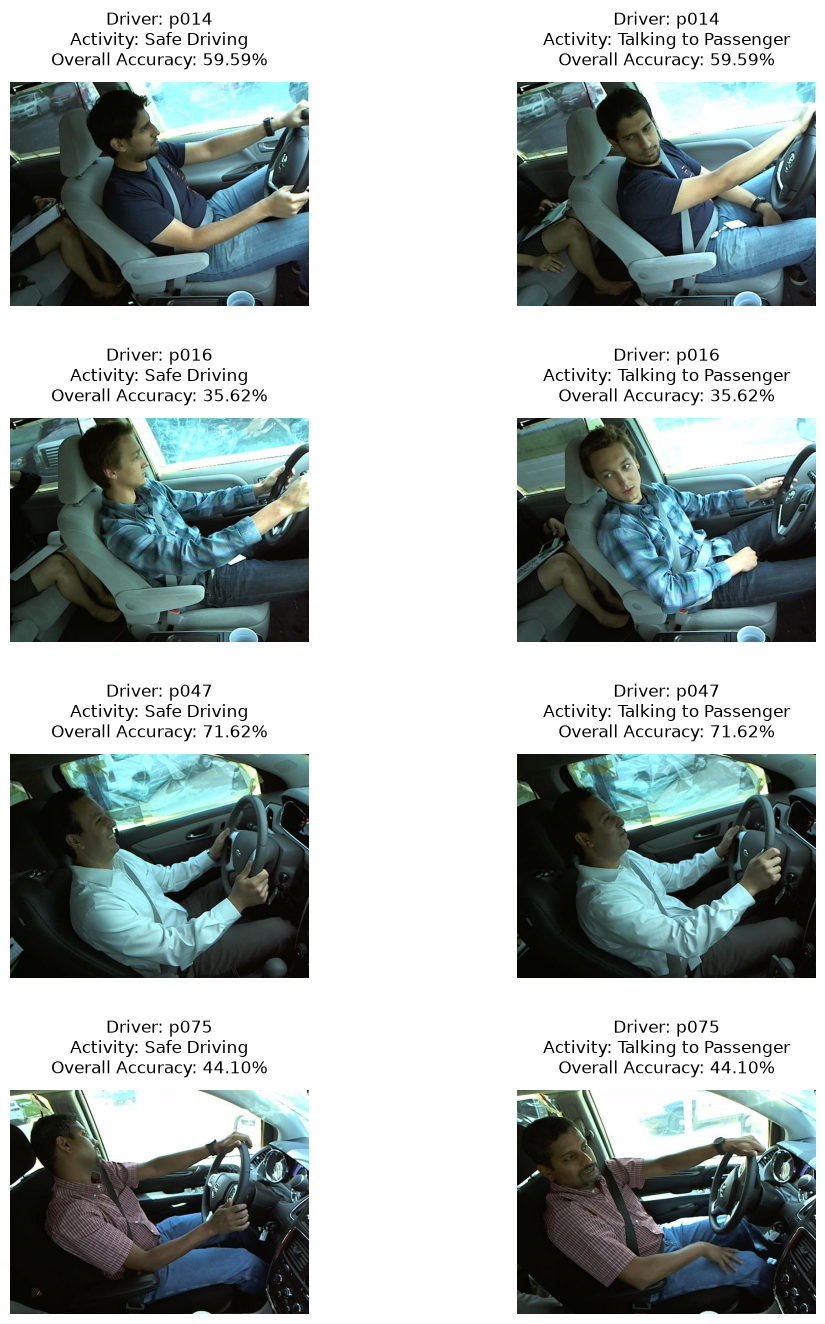

In [12]:
import matplotlib.pyplot as plt

# Four validation drivers
drivers = sorted(val_df["subject"].unique())

image_dir = ROOT / "data/raw/imgs/train"

# Display safe driving and passenger interaction
classes_to_show = ["c0", "c9"]

fig, axes = plt.subplots(4, 2, figsize=(12, 16))

for i, driver in enumerate(drivers):

    # Get overall accuracy for this driver
    accuracy = driver_df.loc[
        driver_df["driver"] == driver, "accuracy"
    ].iloc[0]

    for j, cls in enumerate(classes_to_show):

        # Find an image from this driver and class
        subset = val_df[
            (val_df["subject"] == driver) &
            (val_df["classname"] == cls)
        ]

        if subset.empty:
            axes[i, j].axis("off")
            continue

        sample = subset.iloc[len(subset) // 2]

        image_path = (
            image_dir /
            sample["classname"] /
            sample["img"]
        )

        image = plt.imread(image_path)

        axes[i, j].imshow(image)

        axes[i, j].set_title(
            f"Driver: {driver}\n"
            f"Activity: {class_names[cls]}\n"
            f"Overall Accuracy: {accuracy:.2%}",
            fontsize=12,
            pad=12
        )

        axes[i, j].axis("off")

plt.subplots_adjust(hspace=0.5, wspace=0.2)

plt.show()

## 10. Driver × Activity Recall Analysis

Compare classification recall across all ten activities
for each unseen validation driver.

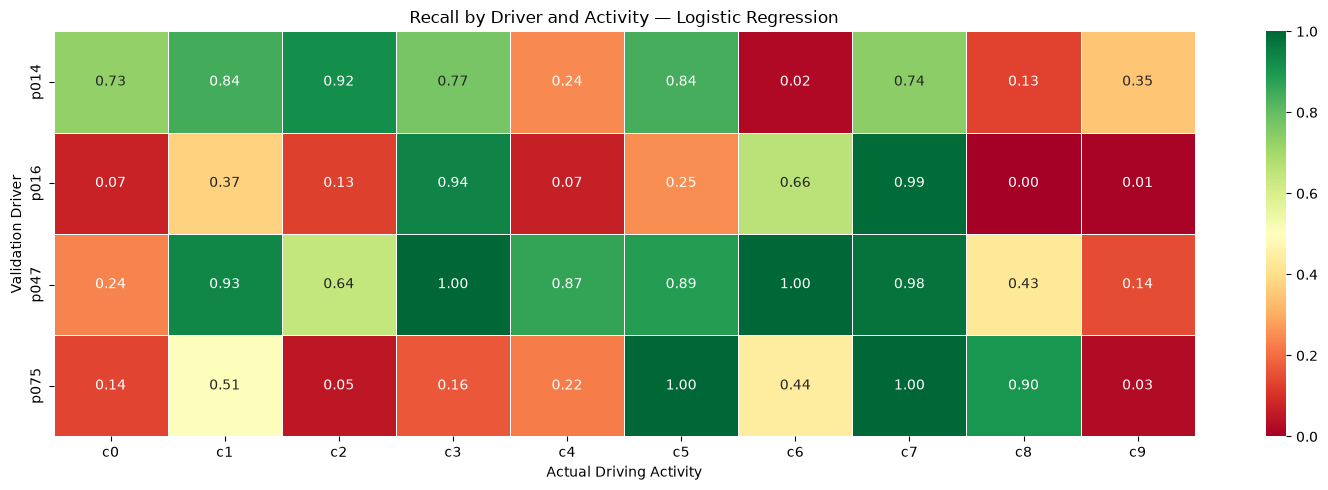

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate recall for every driver and activity
driver_class_results = (
    error_df
    .groupby(["subject", "actual"])["correct"]
    .agg(["sum", "count"])
    .reset_index()
)

driver_class_results["recall"] = (
    driver_class_results["sum"] /
    driver_class_results["count"]
)

# Create driver × activity matrix
recall_matrix = driver_class_results.pivot(
    index="subject",
    columns="actual",
    values="recall"
)

recall_matrix = recall_matrix.reindex(
    columns=sorted(class_names.keys())
)

# Visualize
plt.figure(figsize=(15, 5))

sns.heatmap(
    recall_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title("Recall by Driver and Activity — Logistic Regression")
plt.xlabel("Actual Driving Activity")
plt.ylabel("Validation Driver")

plt.tight_layout()

# Save results
recall_matrix.to_csv(
    error_dir / "driver_class_recall.csv"
)

plt.savefig(
    error_dir / "driver_class_recall_heatmap.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 10. Driver-Specific Error Analysis: Recall Across Driving Activities

### 10.1 Objective

To investigate the generalization capabilities of the HOG-based Logistic Regression classifier, we conducted a driver-specific error analysis using four previously unseen validation drivers (p014, p016, p047, and p075).

Unlike overall classification accuracy, which summarizes performance across all images, this analysis examines how reliably the model recognizes each of the ten driving activities for individual drivers.

Class-wise recall was calculated as:

\[
\text{Recall} = \frac{TP}{TP + FN}
\]

where TP represents correctly classified images of a particular activity and FN represents images of that activity incorrectly assigned to other classes.

The results were visualized using a driver-by-activity recall heatmap.

### 10.2 Overall Driver Performance

The model demonstrated substantial variation in performance across validation drivers.

| Driver | Accuracy | Macro-F1 |
|---|---:|---:|
| p014 | 59.59% | 51.92% |
| p016 | 35.62% | 27.31% |
| p047 | 71.62% | 69.39% |
| p075 | 44.10% | 41.97% |

The difference between the highest-performing driver (p047) and the lowest-performing driver (p016) was approximately **36 percentage points**.

This substantial variation indicates that the classifier's ability to recognize distracted driving activities is strongly dependent on the characteristics of the individual driver and their recorded images.

Although all four individuals were excluded from model training, the classifier generalized considerably better to some drivers than others.

### 10.3 Key Findings From the Recall Heatmap

**Finding 1: Some activities generalize consistently across drivers.**

Class c7 (Reaching Behind) demonstrated relatively strong performance for all four validation drivers.

Its recall values were:

- p014: 74%
- p016: 99%
- p047: 98%
- p075: 100%

These results suggest that reaching behind produces relatively distinctive visual configurations that can be recognized using HOG features.

The activity often involves substantial changes in arm and upper-body orientation, potentially creating recognizable gradient patterns.

Similarly, class c5 (Operating Radio) performed reasonably well for three drivers, achieving 84% recall for p014, 89% for p047, and 100% for p075. However, recall declined to 25% for p016, demonstrating that even relatively recognizable activities may exhibit driver-specific difficulties.

**Finding 2: Recognition of the same activity varies substantially across drivers.**

Several activities exhibited extreme differences in recall.

For example, c3 (Texting with Left Hand) achieved:

| Driver | c3 Recall |
|---|---:|
| p014 | 77% |
| p016 | 94% |
| p047 | 100% |
| p075 | 16% |

The 84-percentage-point difference between p047 and p075 indicates that the classifier does not consistently recognize the same activity across individuals.

Similar variation occurred for c6 (Drinking), with recall ranging from 2% for p014 to 100% for p047.

These differences suggest that the model may rely on visual configurations that are not sufficiently invariant to changes in driver posture, appearance, or activity execution.

However, the heatmap alone cannot determine which of these factors causes the observed differences.

**Finding 3: Talking to Passenger is consistently difficult.**

Class c9 (Talking to Passenger) achieved the following recall:

| Driver | c9 Recall |
|---|---:|
| p014 | 35% |
| p016 | 1% |
| p047 | 14% |
| p075 | 3% |

Unlike c7, which performed strongly across drivers, c9 showed consistently low recall.

Even the best-performing driver for this activity achieved only approximately 35% recall.

The poor recognition of passenger interaction appears to be a general limitation of the HOG-based classifier rather than a problem restricted to one individual.

Visual inspection showed that passenger interaction can involve different head orientations, arm positions, and body postures.

Furthermore, these configurations may resemble other activities, particularly safe driving, texting, or operating the radio.

This creates substantial ambiguity when attempting to recognize passenger interaction from a single image using handcrafted gradient features.

**Finding 4: High overall accuracy can conceal poor performance on specific activities.**

Driver p047 achieved the highest overall accuracy at 71.62%.

However, its recall for c9 was only 14%.

Similarly, driver p014 achieved 59.59% overall accuracy but only 2% recall for drinking (c6) and 13% recall for hair and makeup (c8).

These findings demonstrate that overall accuracy alone is insufficient for evaluating driver-monitoring systems.

A model may achieve relatively strong aggregate performance while failing to recognize particular forms of distracted driving.

Therefore, per-class recall and Macro-F1 should be considered alongside overall accuracy when comparing subsequent models.

### 10.4 Interpretation: Limitations of HOG and Logistic Regression

The observed patterns suggest several potential limitations of the classical machine learning approach.

First, HOG features describe local edge orientations rather than explicitly modeling human body parts, objects, or activity semantics.

Activities involving large and distinctive movements, such as reaching behind, may therefore be easier to recognize.

In contrast, activities involving subtle differences in hand placement or head orientation may generate overlapping feature representations.

Second, Logistic Regression uses linear decision boundaries in the HOG feature space.

Although this approach can effectively distinguish some visual patterns, complex human activities may require nonlinear relationships between multiple image regions.

Third, the substantial variation across drivers suggests that the classifier may not have learned representations that are sufficiently robust to individual differences.

Factors such as camera perspective, body posture, clothing texture, illumination, and background structure could influence the extracted HOG features.

Further controlled experiments would be necessary to determine the contribution of each factor.

### 10.5 Implications for Deep Learning Experiments

These findings motivate evaluating convolutional neural networks and transfer learning approaches.

Unlike handcrafted HOG descriptors, CNNs can learn hierarchical visual representations directly from images.

They may capture more discriminative features associated with hand positions, head orientation, object interactions, and spatial relationships.

Pretrained CNN architectures may also provide representations that generalize more effectively across individuals.

However, these improvements are hypotheses that must be tested experimentally.

CNNs may still struggle with activities that are inherently ambiguous in individual images, and they may also learn driver-specific visual shortcuts.

To evaluate whether deep learning improves generalization, subsequent experiments should compare:

1. Overall validation accuracy and Macro-F1.
2. Per-class recall, particularly for difficult activities such as c9.
3. Accuracy and Macro-F1 for each unseen driver.
4. Differences between the best-performing and worst-performing drivers.
5. Common classification errors and confusion patterns.

All comparisons should use the same driver-independent dataset partition to ensure consistency.

### 10.6 Conclusion

The driver-specific analysis revealed substantial limitations in the generalization performance of HOG-based Logistic Regression.

Although the classifier achieved 51.71% overall validation accuracy, performance varied significantly across the four unseen drivers.

Some activities, particularly reaching behind (c7), were recognized consistently across individuals. In contrast, talking to passengers (c9) remained difficult for all drivers.

Other activities exhibited large differences in recall between individuals, suggesting that the learned visual representations may be sensitive to driver-specific characteristics.

These findings demonstrate that overall classification accuracy does not fully describe the reliability of distracted driving recognition systems.

Driver-independent evaluation, per-class recall, and per-driver performance are essential for identifying weaknesses that may otherwise remain hidden.

The results provide a clear experimental motivation for evaluating learned visual representations through CNN architectures and transfer learning, with particular emphasis on robust generalization to unseen drivers.